In [1]:
from langchain_community.document_loaders import TextLoader, DirectoryLoader
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from pathlib import Path
from dotenv import load_dotenv

C:\Users\asus\AppData\Local\Temp\ipykernel_9504\2047418069.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader, DirectoryLoader


In [2]:
# load the api keys
load_dotenv()

True

In [3]:
# create the llm and embedding model

llm = ChatOpenAI(model="gpt-5-mini")

embedder = OpenAIEmbeddings(model="text-embedding-3-small",
                            dimensions=1024) # 1536

In [4]:
# load the docs from source

loader = DirectoryLoader(path=Path("cleaned-transcripts").as_posix(),
                         loader_cls=TextLoader,
                         show_progress=True)

docs = loader.load()

100%|██████████| 14/14 [00:00<00:00, 61.51it/s]


In [5]:
docs[0].page_content[0:1000]

"00:00:00.000 --> 00:00:29.000\nPakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.\n\n00:00:30.000 --> 00:00:34.000\nYou are from Kharrawala, you are from Kharwala, I am from Miawala\n\n00:00:37.000 --> 00:00:40.000\nCome on, perfect\n\n00:00:40.000 --> 00:00:44.000\nOkay, let's begin\n\n00:00:44.000 --> 00:00:46.000\nFirst of all, I will introduce myself\n\n00:00:46.000 --> 00:00:50.000\nHas anyone seen me or taken any course of mine before?\n\n00:00:50.000 --> 00:00:53.000\nAnyone? Yes or no please?\n\n00:00:53.000 --> 00:00:56.000\nOkay, fine\n\n00:00:56.000 --> 00:00:59.000\nNo worries, let me tell you about myself\n\n00:00:59.000 --> 00:01:02.000\nI am Ajay, I belong to Uttarakhand\n\n00:01:02.000 --> 00:01:05.000\nAnd I have been working with CampusX for the last two years\n\n00:01:05.000 --> 00:01:09.000\nI am working on the Data Analytics and AI part on CampusX\n\n00:01:09.000 --> 00:01:13.000\nAnd in the last two years, I have delivered

In [7]:
# chunk the text, sized in tokens (o200k_base matches the gpt-5 model family)
# to mirror DeepEval's ContextConstructionConfig chunk sizing

chunker = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="o200k_base",
    chunk_size=1024,
    chunk_overlap=0)

chunks = chunker.split_documents(docs)

In [8]:
print(f"Chunks: {len(chunks)}")

Chunks: 973


In [9]:
# vector store

vs = Chroma(collection_name="rag_demo",
            embedding_function=embedder,
            persist_directory=Path("../saved-embeddings").as_posix())

# add docs

vs.add_documents(chunks)

['4b58f5b2-451d-4c7c-8c8d-4e2c0826efc1',
 '94e603a6-71ea-465d-ac48-2361af4d7013',
 'a61bc23a-d4b5-4444-aa45-b733eda0ae86',
 'd6929de4-4e7d-4599-bb56-b74cce798e55',
 'c83efd97-6a62-4b99-bcef-100045177130',
 '7860ea77-64f4-4f5c-9ff7-eac711a8294b',
 'e3c22d5e-459c-4152-8b28-d4ee812fe7af',
 'bbfdad54-9b2b-4dde-b3e7-af9429c7e9e9',
 'bffb349b-e41e-4307-8cce-150525b260c8',
 '2792a449-a426-4673-9620-4be9beba51a8',
 '9881b91a-fca0-4477-82fc-c33ab4bdccc9',
 'b2df42eb-7beb-4c11-97f5-34b8432f5168',
 'bd98cf8a-8be2-40a8-9ea7-004970ce9a38',
 '4ea4a4b5-e441-4f59-b56b-682b77fcc206',
 '13ca1722-3972-4eb1-a9f5-747a7fa7598f',
 'a8c6cee9-ab6e-4416-a99f-422e9ea679b9',
 '1d1e8f47-84d2-4d37-9889-e0dba5029894',
 'a79cb969-c62f-4d5a-b061-353ba04bc39f',
 '6ec3b1d5-c255-40d3-98b6-464609995c31',
 '9657462a-28ae-4a10-9dc4-dc5fa874a2f0',
 'f8455958-c8ed-4491-9ad7-0df3eebbd271',
 '18869267-2f76-4f6b-9e7f-a16aca81b376',
 '31364b52-4ad3-4548-927e-b2f1c4746651',
 '9ba56fdf-a10d-4eee-829b-ec2f2ec6d750',
 '26f0527c-1a80-

In [10]:
# create the retriever

retriever = vs.as_retriever(search_kwargs={"k":3})

In [12]:
from langgraph.graph import StateGraph, START, END
from typing import Literal, TypedDict

class RAGState(TypedDict):
    
    query: str 
    retrieved_docs: list[Document]
    context: str 
    prompt: ChatPromptTemplate
    response: str

In [13]:
def retrieve(state: RAGState) -> dict:
    query = state["query"]
    retrieved_docs = retriever.invoke(query)
    
    context = "\n\n".join([doc.page_content for doc in retrieved_docs])
    return {"retrieved_docs":retrieved_docs,
            "context":context}

In [14]:
def augmentation(state: RAGState) -> dict:

    prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a helpful assistant. Answer the user query
                      based on the given context only. If you do not know the answer
                      say I don't know. Do not add any preamble to the response"""),
        ("human", "context: {context}\n\nquery: {query}")
    ])
    
    return {"prompt": prompt}

In [15]:
from langchain_core.output_parsers import StrOutputParser
def generation(state: RAGState) -> dict:
    
    query = state["query"]
    context = state["context"]
    prompt = state["prompt"]
    
    rag_chain = prompt | llm | StrOutputParser()
    response = rag_chain.invoke({"context":context, "query":query})
    
    return {"response":response}

In [16]:
# create the graph
graph_builder = StateGraph(RAGState)

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("augmentation", augmentation)
graph_builder.add_node("generation", generation)

graph_builder.add_edge(START,"retrieve")
graph_builder.add_edge("retrieve","augmentation")
graph_builder.add_edge("augmentation","generation")
graph_builder.add_edge("generation",END)

graph = graph_builder.compile()

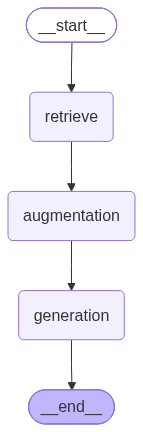

In [17]:
graph

In [18]:
result = graph.invoke({"query": "how much fine was imposed on the lawyer who used fake evidences from chatgpt"})

In [19]:
print(result["response"])

About $5,000.


In [20]:
result["context"]

"00:25:22.320 --> 00:25:30.320\nThe dealer made a chatbot so that they could deal with customers.\n\n00:25:30.320 --> 00:25:36.320\nSo a person went and started chatting with the chatbot.\n\n00:25:36.320 --> 00:25:41.320\nAnd he felt that there is a potential that I can do anything with this chatbot.\n\n00:25:41.320 --> 00:25:46.320\nSo what he did was he prompted the chatbot in such a way that he said\n\n00:25:46.320 --> 00:25:53.320\nsince I am your customer, you are obliged to follow whatever I say.\n\n00:25:53.320 --> 00:25:56.320\nSo whatever I say, you have to listen to it.\n\n00:25:56.320 --> 00:26:00.320\nSo in a way, this person jailbreak the chatbot.\n\n00:26:00.320 --> 00:26:04.320\nAnd he said that I like this particular car.\n\n00:26:04.320 --> 00:26:08.320\nYou offer me this car for $1.\n\n00:26:08.320 --> 00:26:12.320\nAnd your chatbot agreed.\n\n00:26:12.320 --> 00:26:15.320\nNot only did he agree, he also released a binding offer.\n\n00:26:15.320 --> 00:26:21.320\nAnd 